# 06 Forecasts: demand, trends and online-hiring signals

This notebook forecasts short-term job demand and selected online-hiring signals. The available history is limited, so the forecast stays short and keeps uncertainty visible.

## 1. Forecast setup

The reliable history contains only 37 days, so the forecast covers the next 14 days, from 24 March to 6 April 2024.

Days 1 to 7 are the main forecast. Days 8 to 14 are an extended short-term outlook with more uncertainty because there is less historical evidence for evaluating a two-week forecast.

Four simple forecasting models are compared:

- Seasonal baseline: uses the value from the same weekday one week earlier.
- Weekday mean: uses the recent average for that weekday.
- Trend with weekday adjustment: combines a time trend with normal weekday differences.
- Damped trend with weekday adjustment: uses the same idea but reduces how strongly the trend continues into the future.

Simple models are used because the history is short. A more complex model would have very little data available for learning and testing.

### Model selection

The first 30 days, from 16 February to 16 March, form the development period. The final 7 days, from 17 to 23 March, stay separate for final evaluation.

Inside the development period, rolling backtests repeatedly train on earlier days and forecast the next 7 days. This shows how each model performs across several points in the available history.

Two groups are evaluated separately:

- demand: total jobs and the 23 category series;
- online-hiring signals: hourly-job share, North American client share and client-country concentration.

The model with the lowest average seasonal MASE across the series in a group is selected. This rule is fixed before any results are seen. The same selected model is then used across all series in that group rather than choosing a different model for every category.

### Forecast consistency

Total jobs and category shares are forecast together. Category shares stay between 0 and 1 and are scaled so all 22 job categories plus Other / Unclear add up to the total forecast.

### Error measures

- MAE shows the average size of the forecast error.
- Seasonal MASE compares the model error with the usual week-to-week change. Lower values are better.
- Relative MAE compares a model directly with the seasonal baseline. A value below 1 means the model performs better than the baseline.

MAPE is not used because percentage errors become unstable for small category counts.

In [1]:
from job_market.notebook import start

project = start()

RUN_ID: 20261011T132714Z-e537465460
Source: data/raw/all_upwork_jobs_2024-02-07-2024-03-24.csv (244,828 rows)
Taxonomy version: 1.0
Verified outputs: 54 file(s), all hashes match
Environment: matches environment.yml


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from job_market.taxonomy import CATEGORIES, OTHER

pd.set_option("display.max_colwidth", 50)
pd.set_option("display.width", 170)

choice = project.read_csv("forecast_model_choice.csv")
by_series = project.read_csv("forecast_backtest_by_series.csv")
long_check = project.read_csv("forecast_backtest_14d.csv")
final = project.read_csv("forecast_final_evaluation.csv")
demand_daily = project.read_csv("forecast_demand_daily.csv", parse_dates=["date"])
outlook = project.read_csv("forecast_demand_outlook.csv")
signals_daily = project.read_csv("forecast_signals_daily.csv", parse_dates=["date"])
signals_outlook = project.read_csv("forecast_signals_outlook.csv")
history = project.read_csv("trend_category_daily.csv", parse_dates=["date"])
remote_daily = project.read_csv("remote_daily.csv", parse_dates=["date"])
rules = project.settings.section("forecast")

NAMES = {key: name for key, (name, _) in CATEGORIES.items()}
NAMES["total"] = "All jobs"
winners = choice[choice["chosen"]].set_index("family")["model"]
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#b8b6b0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10, "legend.frameon": False,
})
print(f"Forecast: {demand_daily['date'].min():%d %b} to {demand_daily['date'].max():%d %b %Y}; "
      f"damping {rules['damping_phi']}; winners: demand = {winners['demand']}, signals = {winners['signals']}")

Forecast: 24 Mar to 06 Apr 2024; damping 0.9; winners: demand = weekday_mean, signals = weekday_mean


## 2. Model selection results

### 2.1 Rolling backtest
The table compares average forecast error across all series in each group, using 10 rolling backtest origins and forecast days 1 to 7 from the development period.

In [3]:
choice.round(3)

,family,model,mase,relative_mae,chosen
0,demand,weekday_mean,0.771,1.009,True
1,demand,damped_trend,0.821,1.009,False
2,demand,trend_weekday,0.842,1.040,False
3,demand,seasonal_naive,0.859,1.000,False
4,signals,weekday_mean,0.560,0.959,True
5,signals,damped_trend,0.605,1.007,False
6,signals,seasonal_naive,0.606,1.000,False
7,signals,trend_weekday,0.633,1.049,False


In [4]:
demand_series = by_series[(by_series["family"] == "demand")]
wins = demand_series[demand_series["model"] == winners["demand"]]
print(f"Demand series where {winners['demand']} beats the baseline in development: "
      f"{int((wins['relative_mae'] < 1).sum())} of {len(wins)}")
pivot = demand_series.pivot(index="series", columns="model", values="relative_mae")
pivot.index = pivot.index.map(NAMES)
pivot.round(2).sort_values(winners["demand"])

Demand series where weekday_mean beats the baseline in development: 17 of 24


model,damped_trend,seasonal_naive,trend_weekday,weekday_mean
series,,,,
Customer Service,1.06,1.0,1.11,0.62
Mobile Development,0.78,1.0,0.80,0.63
Video & Animation,0.94,1.0,1.00,0.70
Software & IT,0.78,1.0,0.79,0.71
Legal,0.73,1.0,0.75,0.72
Audio & Music,1.00,1.0,1.02,0.78
Engineering & Architecture,0.72,1.0,0.73,0.79
Web Development,1.08,1.0,1.13,0.80
Sales & Lead Generation,0.93,1.0,0.94,0.84


- The selection rule, fixed before evaluation, picks the model with the lowest average seasonal MASE across the series in each group. The weekday-mean model has the lowest value in both groups: 0.77 against 0.86 for the seasonal baseline for demand, and 0.56 against 0.61 for the signals.
- Relative MAE gives a less favourable result. For demand, the weekday-mean average is 1.01, about 1% worse than the seasonal baseline and level with the damped trend.
- Across the 23 category series (22 job categories plus Other / Unclear), the weekday-mean model beats the baseline in 17. It is worse in the other 6, most clearly Writing & Content (2.27), Admin & Virtual Assistance (1.59), AI & Machine Learning (1.41) and Translation & Transcription (1.41). The change in posting patterns around 26 February may contribute to these errors.
- Total jobs is a separate series. For total jobs, the weekday-mean model has a Relative MAE of 1.52, so it is worse than the baseline.
- For the online-hiring signals, the average Relative MAE of 0.96 comes from hourly-job share alone (0.65). The model is worse than the baseline for North American client share (1.18) and client-country concentration (1.06).
- Both trend models have higher MASE than the weekday-mean model in both groups, so continuing the recent trend does not improve the main forecast.

### 2.2 14-day check
Only 3 backtest origins allow a full 14-day forecast inside the development period. This gives a useful check for days 8 to 14, but it is not strong enough to treat as a full evaluation.

In [5]:
long_check.round(3)

,family,model,mase,relative_mae,origins
0,demand,weekday_mean,0.827,1.040,3
1,demand,seasonal_naive,0.866,1.000,3
2,demand,damped_trend,0.927,1.110,3
3,demand,trend_weekday,1.070,1.319,3
4,signals,weekday_mean,0.491,0.999,3
5,signals,seasonal_naive,0.518,1.000,3
6,signals,damped_trend,0.672,1.331,3
7,signals,trend_weekday,0.991,1.988,3


In the 14-day check, the weekday-mean model again has the lowest average MASE in both groups, but the order of the other models changes: the seasonal baseline moves to second place. On Relative MAE, the weekday-mean model is about 4% worse than the baseline for demand (1.04) and level with it for the signals (1.00). With only 3 origins, this is weak evidence for days 8 to 14.

### 2.3 Reserved final week: 17 to 23 March
After model selection is complete, the chosen models are fitted on the development period and evaluated once on the final 7 days.

In [6]:
summary_final = final.groupby(["family", "model"])[["mase", "relative_mae"]].mean().round(3)
summary_final["chosen"] = [winners[f] == m for f, m in summary_final.index]
summary_final

mase  relative_mae  chosen
family  model                                      
demand  damped_trend    0.828         0.860   False
        seasonal_naive  0.987         1.000   False
        trend_weekday   0.840         0.874   False
        weekday_mean    0.836         0.868    True
signals damped_trend    0.505         0.770   False
        seasonal_naive  0.627         1.000   False
        trend_weekday   0.527         0.793   False
        weekday_mean    0.559         0.976    True

In [7]:
cats_final = final[(final["family"] == "demand") & (final["series"] != "total") & (final["model"] == winners["demand"])]
beats_final = int((cats_final["relative_mae"] < 1).sum())
print(f"Category series (22 + Other) where the winner beats the baseline in the final window: {beats_final} of {len(cats_final)}")
final[(final["series"] == "total")].round(3)

Category series (22 + Other) where the winner beats the baseline in the final window: 20 of 23


,family,model,series,mae,mase,relative_mae,chosen
0,demand,seasonal_naive,total,72.143,0.389,1.000,False
24,demand,weekday_mean,total,112.000,0.603,1.552,True
48,demand,trend_weekday,total,108.084,0.582,1.498,False
72,demand,damped_trend,total,115.188,0.621,1.597,False


In [8]:
final[final["family"] == "signals"].pivot(index="series", columns="model", values="relative_mae").round(3)

model,damped_trend,seasonal_naive,trend_weekday,weekday_mean
series,,,,
hhi,0.787,1.0,0.787,1.150
hourly_share,0.899,1.0,0.967,0.653
north_america_share,0.623,1.0,0.625,1.125


- The weekday-mean model performs better than the seasonal baseline for 20 of the 23 category series in the final week, with an average Relative MAE of about 0.84. It performs worse for Video & Animation (1.19), Accounting & Finance (1.18) and HR & Recruiting (1.08).
- Across all 24 demand series, the damped-trend model has a slightly lower average MASE than the weekday-mean model: 0.828 compared with 0.836. Each series counts equally in this average.
- For total jobs, the weekday-mean model performs worse than the seasonal baseline in both evaluations. Its Relative MAE is 1.52 during development and 1.55 in the final week. In the final week, its mean absolute error is 112 jobs per day, compared with 72 for the baseline.
- For the online-hiring signals, the weekday-mean model beats the baseline only for hourly-job share. The damped trend has the lowest average error in this group for the final week.
- The selected model remains unchanged because model selection uses the development results, not the final-week results.

### 2.4 Forecast ranges and coverage
- For days 1 to 7, the range comes from past forecast errors. In each of the 10 development backtests, the selected model's error is divided by the series' usual week-to-week change, so errors from large and small series can be pooled. The 10th and 90th percentiles of these errors, for each forecast day, form the intended 80% range.
- The range reflects historical forecast errors only. It adds no separate uncertainty for the choice of model or the fitted model values, and it assumes the next two weeks behave like the development period. It is not a guaranteed 80% prediction interval.
- For days 8 to 14, the day 7 range is widened by the square root of (forecast day ÷ 7). This is a fixed assumption, because only 3 backtests give full two-week errors.
- Demand lower limits stop at 0 jobs, and signal ranges stay between 0 and 1.

The forecast ranges aim to contain the actual value about 80% of the time. Their coverage is checked on the final seven days, which are separate from model selection. The ranges for this check are rebuilt using only the development period.

In [9]:
SIGNAL_NAMES = {"hourly_share": "Hourly share of jobs", "north_america_share": "North American client share",
                "hhi": "Client concentration (HHI)"}
coverage = project.read_csv("forecast_final_coverage.csv")
pooled = coverage[coverage["series"] == "pooled"].set_index("family")
for family, row in pooled.iterrows():
    print(f"{family}: {int(row['inside'])} of {int(row['valid'])} series-days inside the range "
          f"({100 * row['coverage']:.1f}%); undefined days: {int(row['undefined'])}")
cov_series = coverage[coverage["series"] != "pooled"].copy()
cov_series["name"] = cov_series["series"].map({**NAMES, **SIGNAL_NAMES})
cov_series["days inside"] = cov_series["inside"].astype(int).astype(str) + " of " + cov_series["valid"].astype(int).astype(str)
cov_series["coverage (%)"] = (100 * cov_series["coverage"]).round(1)
cov_series.sort_values(["family", "coverage"])[["family", "name", "days inside", "coverage (%)"]].set_index("name")

demand: 126 of 168 series-days inside the range (75.0%); undefined days: 0
signals: 16 of 21 series-days inside the range (76.2%); undefined days: 0


,family,days inside,coverage (%)
name,,,
Data & Analytics,demand,2 of 7,28.6
AI & Machine Learning,demand,3 of 7,42.9
Video & Animation,demand,4 of 7,57.1
Accounting & Finance,demand,4 of 7,57.1
Audio & Music,demand,4 of 7,57.1
E-commerce Operations,demand,4 of 7,57.1
"Business, Project Management & Consulting",demand,4 of 7,57.1
Mobile Development,demand,5 of 7,71.4
Software & IT,demand,5 of 7,71.4


For demand, 126 of 168 series-days fall inside the ranges (75.0%). For the online-hiring signals, 16 of 21 series-days fall inside (76.2%).

Both results are below the intended 80%. Coverage also varies between series. Data & Analytics has 2 of 7 days inside its range, and AI & Machine Learning has 3 of 7. Total jobs and four categories have all 7 days inside their ranges.

These figures come from one evaluation week only. Days within a series are related, so they do not provide 168 independent observations. The results do not establish how often the ranges contain actual values in future weeks. The wider ranges for days 8 to 14 have no separate coverage test.

## 3. Task 3: Which categories have the highest expected demand?
- The forecast reports expected jobs per day for each category over the next 14 days.
- The ranges are the 80% ranges described in section 2.4.
- The weekly values shown below are averages of the daily forecasts, so they describe a typical day in the week rather than a weekly total.

In [10]:
ranking = outlook[outlook["series"] != "total"].sort_values("rank_1_7").copy()
ranking["name"] = ranking["series"].map(NAMES)
ranking["range overlaps next rank"] = (ranking["low_1_7"] <= ranking["high_1_7"].shift(-1)).map({True: "yes", False: ""})
ranking[["rank_1_7", "name", "recent_jobs_per_day", "forecast_jobs_per_day_1_7", "low_1_7", "high_1_7",
         "forecast_jobs_per_day_8_14", "low_8_14", "high_8_14", "range overlaps next rank"]].set_index("rank_1_7").round(1)

,name,recent_jobs_per_day,forecast_jobs_per_day_1_7,low_1_7,high_1_7,forecast_jobs_per_day_8_14,low_8_14,high_8_14,range overlaps next rank
rank_1_7,,,,,,,,,
1.0,Web Development,899.3,897.4,844.1,949.4,897.4,830.8,954.5,
2.0,Other / Unclear,770.9,758.5,710.1,805.6,758.5,697.9,810.3,yes
3.0,Design & Creative,714.4,716.3,662.7,768.5,716.3,649.3,773.7,yes
4.0,Digital Marketing,646.9,662.8,615.6,708.9,662.8,603.8,713.4,
5.0,Software & IT,468.0,465.2,433.6,495.9,465.2,425.7,499.0,yes
6.0,Video & Animation,411.4,420.2,386.7,452.7,420.2,378.4,455.9,
7.0,Writing & Content,245.0,257.2,195.7,317.1,257.2,180.3,323.0,yes
8.0,Sales & Lead Generation,253.9,250.4,223.5,276.5,250.4,216.8,279.1,yes
9.0,Admin & Virtual Assistance,224.7,227.7,172.1,281.8,227.7,158.2,287.1,yes


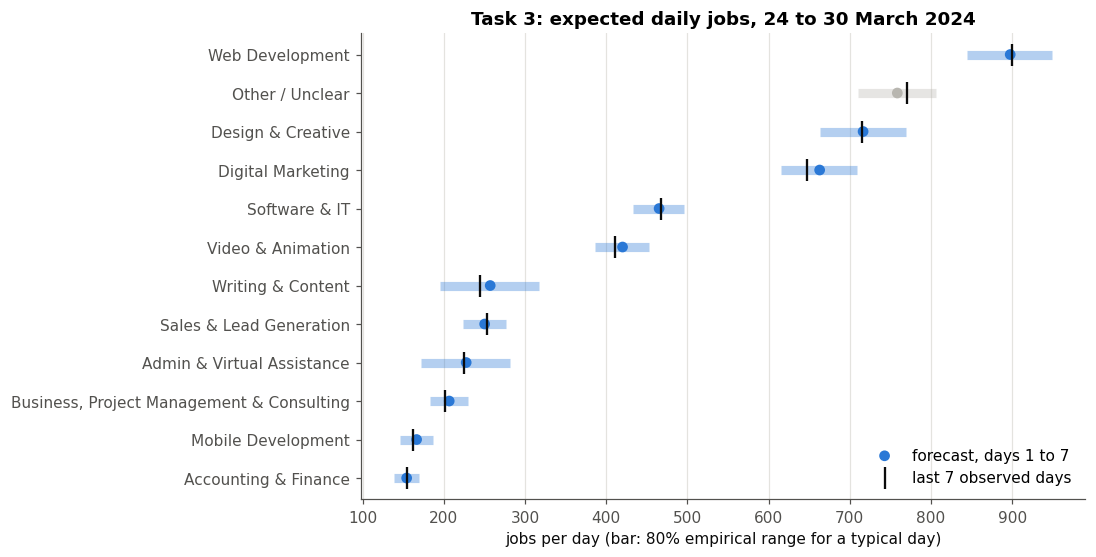

In [11]:
show = ranking.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.5))
y = np.arange(len(show))
colors = [GREY if s == OTHER else BLUE for s in show["series"]]
ax.hlines(y, show["low_1_7"], show["high_1_7"], color=colors, lw=6, alpha=0.35)
ax.scatter(show["forecast_jobs_per_day_1_7"], y, color=colors, zorder=3, label="forecast, days 1 to 7")
ax.scatter(show["recent_jobs_per_day"], y, marker="|", s=200, color=INK, zorder=4, label="last 7 observed days")
ax.set_yticks(y)
ax.set_yticklabels(show["name"])
ax.set_xlabel("jobs per day (bar: 80% empirical range for a typical day)")
ax.set_title("Task 3: expected daily jobs, 24 to 30 March 2024")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

- Web Development has the highest expected demand over the next two weeks at about 900 jobs per day, followed by Design & Creative at about 720 and Digital Marketing at about 660. Software & IT and Video & Animation follow.
- Other / Unclear is also large, at about 760 jobs per day, and remains visible because it is part of the total.
- Many neighbouring categories have overlapping forecast ranges, so small differences in rank do not show a clear difference in demand.
- Overall, the forecast stays close to recent observed levels, with the main variation coming from the normal weekday pattern.

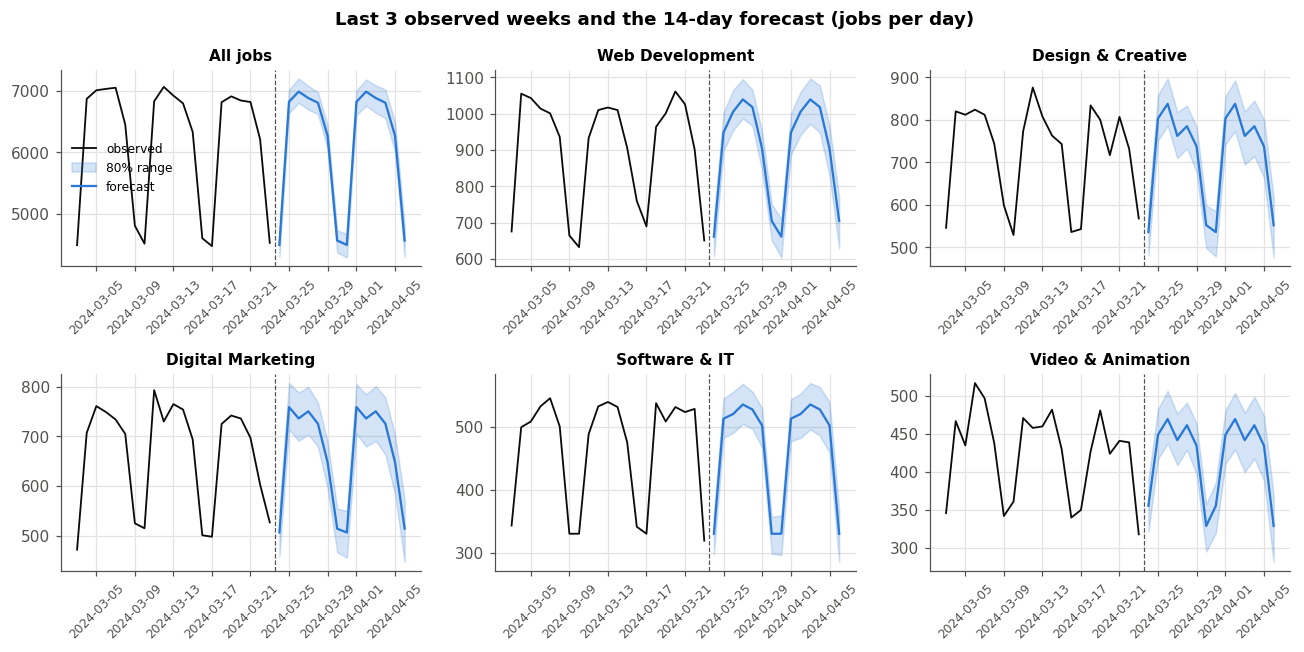

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, series in zip(axes.flat, ["total", "web_development", "design_creative", "digital_marketing", "software_it", "video_animation"]):
    if series == "total":
        past = history.groupby("date")["jobs"].sum()
    else:
        past = history[history["primary_category"] == series].set_index("date")["jobs"]
    future = demand_daily[demand_daily["series"] == series]
    ax.plot(past.index[-21:], past.values[-21:], color=INK, lw=1.2, label="observed")
    ax.fill_between(future["date"], future["low"], future["high"], color=BLUE, alpha=0.2, label="80% range")
    ax.plot(future["date"], future["forecast"], color=BLUE, lw=1.5, label="forecast")
    ax.axvline(future["date"].min() - pd.Timedelta(hours=12), color=MUTED, lw=0.8, ls="--")
    ax.set_title(NAMES[series], fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes.flat[0].legend(fontsize=8)
fig.suptitle("Last 3 observed weeks and the 14-day forecast (jobs per day)", fontweight="bold")
fig.tight_layout()
plt.show()

## 4. Task 8: Which trends are likely to continue?

For each category, the comparison uses:

- the average share from the last 7 observed days;
- the selected forecast for the next 14 days;
- the direction from the better-performing trend model.

Both trend models fit a straight line over all 37 observed days, including the change around 26 February. The damped version reduces the slope by a factor of 0.9 for each day ahead.

A trend direction is shown only when the trend model performs better than the same-weekday baseline in the development backtests. Otherwise, the result is reported as "No reliable direction".

Projected changes smaller than 0.1 percentage points are treated as stable.

In [13]:
trend = outlook[outlook["series"] != "total"].copy()
trend["name"] = trend["series"].map(NAMES)
direction_counts = trend["direction"].value_counts()
print(direction_counts.to_string())
trend[["name", "recent_share_pct", "forecast_share_pct_1_7", "forecast_share_pct_1_14", "trend_model",
       "trend_model_relative_mae", "trend_share_pct_1_14", "trend_change_pp", "direction"]].sort_values(
    ["direction", "trend_change_pp"]).set_index("name").round(3)

direction
no reliable direction    10
stable                    9
rising                    4


,recent_share_pct,forecast_share_pct_1_7,forecast_share_pct_1_14,trend_model,trend_model_relative_mae,trend_share_pct_1_14,trend_change_pp,direction
name,,,,,,,,
Writing & Content,4.023,4.205,4.205,damped_trend,1.228,3.465,-0.557,no reliable direction
Admin & Virtual Assistance,3.674,3.711,3.711,damped_trend,1.145,3.211,-0.463,no reliable direction
Translation & Transcription,1.435,1.587,1.587,damped_trend,1.287,1.225,-0.210,no reliable direction
Other / Unclear,12.665,12.386,12.386,damped_trend,1.097,12.482,-0.183,no reliable direction
Customer Service,1.195,1.062,1.062,damped_trend,1.064,1.086,-0.110,no reliable direction
Data & Analytics,2.457,2.431,2.431,damped_trend,1.184,2.351,-0.107,no reliable direction
Education & Tutoring,1.029,0.990,0.990,damped_trend,1.012,1.002,-0.027,no reliable direction
Audio & Music,1.409,1.415,1.415,damped_trend,1.002,1.399,-0.010,no reliable direction
AI & Machine Learning,1.522,1.491,1.491,trend_weekday,1.410,1.580,0.058,no reliable direction


- Four categories meet the rule for a rising direction under the damped-trend model: Digital Marketing (+0.48 percentage points), Video & Animation (+0.36), Business, Project Management & Consulting (+0.17) and Design & Creative (+0.15). Each value compares the damped-trend model's average share over the next 14 days with the last 7 observed days. These are not forecasts from the selected weekday-mean model.
- The damped-trend model performs better than the seasonal baseline for these four categories during development. The difference is clearer for Digital Marketing and Design & Creative, with Relative MAE of 0.83 each. It is smaller for Video & Animation (0.94), while Business, Project Management & Consulting is almost level with the baseline (0.996).
- However, the trend estimated from 26 February to 23 March (notebook 05, section 1.4) shows no clear upward trend for Digital Marketing, Video & Animation or Design & Creative. For Video & Animation, the later change is −0.14 percentage points, with a 95% interval from −0.37 to +0.09. The forecast increases may therefore reflect part of the earlier change around 26 February rather than continued growth.
- Sales & Lead Generation is classified as stable in the forecast comparison, while AI & Machine Learning has no reliable forecast direction. Both show increases in the later part of the observed period. These results are not necessarily contradictory: the observed trend and the forecast evaluation measure different things.
- Ten categories have no reliable forecast direction because their trend model does not perform better than the baseline. They include Web Development, Writing & Content, Admin & Virtual Assistance, Translation & Transcription and AI & Machine Learning. High expected demand does not necessarily mean rising demand.
- Nine categories are stable under the defined rule.

The projected increases are small, and evidence for continued growth is limited. The five-week history does not support long-term predictions.

## 5. Task 7: Forecasts of online-hiring signals

Three signals have enough data for short-term forecasting:

- hourly-job share;
- North American client share;
- client-country concentration.

Days 1 to 7 use an 80% empirical range from backtest errors. Days 8 to 14 use the wider extended range.

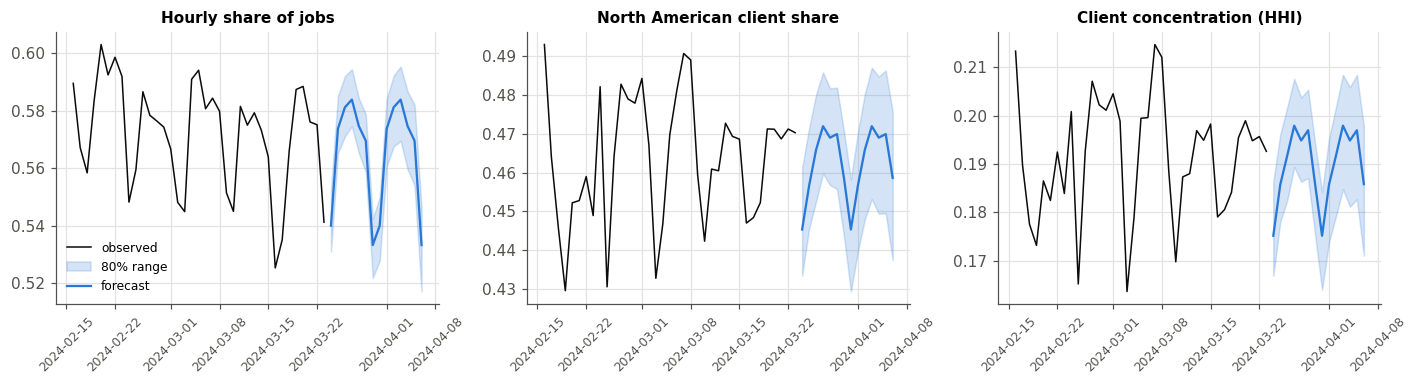

,series,recent_value,forecast_1_7,forecast_1_14,trend_model,trend_model_relative_mae,trend_forecast_1_14,direction
0,hourly_share,0.5670,0.5651,0.5651,damped_trend,1.0844,0.5589,no reliable direction
1,north_america_share,0.4648,0.4625,0.4625,damped_trend,1.0318,0.4654,no reliable direction
2,hhi,0.1917,0.1897,0.1897,damped_trend,0.9037,0.1913,stable


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
labels = {"hourly_share": "Hourly share of jobs", "north_america_share": "North American client share",
          "hhi": "Client concentration (HHI)"}
for ax, series in zip(axes, labels):
    future = signals_daily[signals_daily["series"] == series]
    ax.plot(remote_daily["date"], remote_daily[series], color=INK, lw=1, label="observed")
    ax.fill_between(future["date"], future["low"], future["high"], color=BLUE, alpha=0.2, label="80% range")
    ax.plot(future["date"], future["forecast"], color=BLUE, lw=1.5, label="forecast")
    ax.set_title(labels[series], fontsize=10)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()
signals_outlook.round(4)

- All three online-hiring signals are forecast to stay close to their recent levels. The hourly-job share stays around 57% and the North American client share around 46%. Client-country concentration is equivalent to about 5.3 equally sized countries, based on 1 divided by the HHI.
- The trend models do not support a continuing direction for hourly-job share or North American client share. Client-country concentration changes very little and is treated as stable.
- The three work-arrangement wording series from notebook 05 (remote or home, time-zone requirement, on-site or in-person) are not forecast. They appear in under 1% of job titles, and the forecast step does not model them.

## 6. Summary

- The forecast covers 14 days. Days 1 to 7 are the main forecast, while days 8 to 14 form the extended short-term outlook.
- The weekday-mean model is selected for both forecast groups because it has the lowest average seasonal MASE in the development backtests. On Relative MAE it is about level with the seasonal baseline for demand (1.01), and its advantage for the signals comes from hourly-job share alone.
- In the reserved final week, it beats the seasonal baseline in 20 of the 23 category series. For total jobs, it is worse than the baseline in both the development backtests and the final week.
- The forecast ranges come from historical forecast errors and aim to contain the actual value 80% of the time. In the final week they contain it on 75.0% of demand series-days and 76.2% of signal series-days.
- Web Development has the highest expected demand, followed by Design & Creative and Digital Marketing. Many nearby category ranks have overlapping forecast ranges.
- Under the damped-trend model, four categories meet the rule for a small rise. The support is clearer for Digital Marketing and Design & Creative than for Video & Animation and Business, Project Management & Consulting.
- The later part of the observed period shows no clear upward trend for Digital Marketing, Video & Animation or Design & Creative, so continued growth is not established.
- The hourly-job share, North American client share and client-country concentration are expected to stay close to their recent levels.

### Limitations

- The reliable history covers only five weeks, so the forecasts stay short-term.
- The reserved final evaluation covers only one week, and the coverage check uses 7 days per series. It does not establish future coverage.
- The forecast ranges reflect historical forecast errors only. They add no separate uncertainty for the choice of model or the fitted model values.
- The widening rule for days 8 to 14 is an assumption and has no coverage test.
- The trend models fit a straight line over all 37 days, so their directions are affected by the change around 26 February.
- The data collection process is not fully documented.
- Category forecasts inherit uncertainty from the categorisation system. Categories with low recall may have understated observed counts.

## 7. Claims check

In [15]:
from job_market.trends import trend_fit

bs = by_series.set_index(["family", "series", "model"])["relative_mae"]
dev_wm = by_series[(by_series["family"] == "demand") & (by_series["model"] == "weekday_mean")].set_index("series")["relative_mae"]
dev_cats = dev_wm.drop("total")
dev_sig = by_series[(by_series["family"] == "signals") & (by_series["model"] == "weekday_mean")].set_index("series")["relative_mae"]
lc = long_check.set_index(["family", "model"])
fin = final.set_index(["family", "series", "model"])
fin_avg = final.groupby(["family", "model"])["mase"].mean()
cov_p = coverage[coverage["series"] == "pooled"].set_index("family")
cov_s = coverage[coverage["series"] != "pooled"].set_index("series")
lag = project.settings.section("trends")["newey_west_lag"]
later = {}
for cat in ["digital_marketing", "video_animation", "design_creative", "sales_lead_generation", "ai_ml"]:
    part = history[(history["primary_category"] == cat) & (history["date"] >= "2024-02-26")].sort_values("date")
    later[cat] = trend_fit(part["share"].to_numpy(), part["date"], lag)
rising = ["digital_marketing", "video_animation", "business_project_management", "design_creative"]
ch = choice.set_index(["family", "model"])
rk = ranking.set_index("series")
so = signals_outlook.set_index("series")
tr = trend.set_index("series")
claims = {
    "horizon 24 Mar to 6 Apr": (demand_daily["date"].min() == pd.Timestamp("2024-03-24")
                               and demand_daily["date"].max() == pd.Timestamp("2024-04-06")),
    "damping 0.9": rules["damping_phi"] == 0.9,
    "weekday mean wins both families": winners["demand"] == "weekday_mean" and winners["signals"] == "weekday_mean",
    "demand relative MAE about 1.01": round(ch.loc[("demand", "weekday_mean"), "relative_mae"], 2) == 1.01,
    "signals relative MAE about 0.96": round(ch.loc[("signals", "weekday_mean"), "relative_mae"], 2) == 0.96,
    "trend models worse than weekday mean": all(ch.loc[("demand", m), "mase"] > ch.loc[("demand", "weekday_mean"), "mase"]
                                               for m in ["trend_weekday", "damped_trend"]),
    "3 origins in the 14-day check": int(long_check["origins"].max()) == 3,
    "14-day check: weekday mean best": long_check.sort_values("mase").groupby("family").head(1)["model"].eq("weekday_mean").all(),
    "final: 20 of 23 categories beat baseline": beats_final == 20 and len(cats_final) == 23,
    "final: category relative MAE about 0.84": round(cats_final["relative_mae"].mean(), 2) == 0.84,
    "final: baseline best for total, others about 1.5": all(1.4 <= v <= 1.65 for v in
        final[(final["series"] == "total") & (final["model"] != "seasonal_naive")]["relative_mae"]),
    "final: winner beats baseline for hourly share only": (
        final[(final["family"] == "signals") & (final["model"] == "weekday_mean")].set_index("series")["relative_mae"].lt(1).to_dict()
        == {"hourly_share": True, "north_america_share": False, "hhi": False}),
    "web about 900, design 720, marketing 660": ([round(rk.loc[s, "forecast_jobs_per_day_1_7"], -1) for s in
                                                  ["web_development", "design_creative", "digital_marketing"]] == [900, 720, 660]),
    "other about 760": round(rk.loc[OTHER, "forecast_jobs_per_day_1_7"], -1) == 760,
    "top 3 named functions: web, design, marketing": list(ranking[ranking["series"] != OTHER]["series"].head(3)) ==
        ["web_development", "design_creative", "digital_marketing"],
    "rising: marketing, video, design, business": set(tr.index[tr["direction"] == "rising"]) ==
        {"digital_marketing", "video_animation", "design_creative", "business_project_management"},
    "business only marginal (relative MAE > 0.99)": tr.loc["business_project_management", "trend_model_relative_mae"] > 0.99,
    "gains up to about +0.5 pp": round(tr.loc[tr["direction"] == "rising", "trend_change_pp"].max(), 1) == 0.5,
    "writing/admin/translation/AI: no reliable direction": all(tr.loc[s, "direction"] == "no reliable direction" for s in
        ["writing_content", "admin_virtual_assistance", "translation_transcription", "ai_ml"]),
    "nine stable": int(direction_counts.get("stable", 0)) == 9,
    "hourly about 57%, NA about 46%, HHI equals about 5.3 countries": (
        round(100 * so.loc["hourly_share", "forecast_1_14"]) == 57 and round(100 * so.loc["north_america_share", "forecast_1_14"]) == 46
        and round(1 / so.loc["hhi", "forecast_1_14"], 1) == 5.3),
    "no direction for hourly and NA share; HHI stable": (so.loc["hourly_share", "direction"] == "no reliable direction"
        and so.loc["north_america_share", "direction"] == "no reliable direction" and so.loc["hhi", "direction"] == "stable"),
    "selection MASE: demand 0.77 vs 0.86, signals 0.56 vs 0.61": (
        [round(ch.loc[("demand", m), "mase"], 2) for m in ["weekday_mean", "seasonal_naive"]] == [0.77, 0.86]
        and [round(ch.loc[("signals", m), "mase"], 2) for m in ["weekday_mean", "seasonal_naive"]] == [0.56, 0.61]),
    "demand relative MAE: weekday mean above baseline, level with damped trend": (
        ch.loc[("demand", "weekday_mean"), "relative_mae"] > 1
        and round(ch.loc[("demand", "damped_trend"), "relative_mae"], 2) == 1.01),
    "development: 17 of 23 categories beat baseline; total 1.52": (
        int((dev_cats < 1).sum()) == 17 and len(dev_cats) == 23 and round(dev_wm["total"], 2) == 1.52),
    "development: worst writing 2.27, admin 1.59, AI 1.41, translation 1.41": (
        [round(dev_wm[k], 2) for k in ["writing_content", "admin_virtual_assistance", "ai_ml", "translation_transcription"]]
        == [2.27, 1.59, 1.41, 1.41] and list(dev_cats.nlargest(4).index) == ["writing_content", "admin_virtual_assistance",
                                                                             "ai_ml", "translation_transcription"]),
    "development signals: only hourly share below 1 (0.65, 1.18, 1.06)": (
        [round(dev_sig[k], 2) for k in ["hourly_share", "north_america_share", "hhi"]] == [0.65, 1.18, 1.06]),
    "14-day: baseline second; relative MAE demand 1.04, signals 1.00": (
        list(long_check[long_check["family"] == "demand"].sort_values("mase")["model"].head(2)) == ["weekday_mean", "seasonal_naive"]
        and round(lc.loc[("demand", "weekday_mean"), "relative_mae"], 2) == 1.04
        and round(lc.loc[("signals", "weekday_mean"), "relative_mae"], 2) == 1.00),
    "final: exceptions video 1.19, accounting 1.18, HR 1.08": (
        set(cats_final[cats_final["relative_mae"] >= 1]["series"]) == {"video_animation", "accounting_finance", "hr_recruiting"}
        and [round(fin.loc[("demand", k, "weekday_mean"), "relative_mae"], 2) for k in
             ["video_animation", "accounting_finance", "hr_recruiting"]] == [1.19, 1.18, 1.08]),
    "final: damped trend MASE 0.828 vs 0.836 (demand); lowest for signals": (
        round(fin_avg[("demand", "damped_trend")], 3) == 0.828 and round(fin_avg[("demand", "weekday_mean")], 3) == 0.836
        and fin_avg["signals"].idxmin() == "damped_trend"),
    "total: final 1.55, MAE 112 vs 72": (
        round(fin.loc[("demand", "total", "weekday_mean"), "relative_mae"], 2) == 1.55
        and round(fin.loc[("demand", "total", "weekday_mean"), "mae"]) == 112
        and round(fin.loc[("demand", "total", "seasonal_naive"), "mae"]) == 72),
    "coverage: 126 of 168 (75.0%), 16 of 21 (76.2%), none undefined": (
        (int(cov_p.loc["demand", "inside"]), int(cov_p.loc["demand", "valid"])) == (126, 168)
        and (int(cov_p.loc["signals", "inside"]), int(cov_p.loc["signals", "valid"])) == (16, 21)
        and round(100 * cov_p.loc["demand", "coverage"], 1) == 75.0 and round(100 * cov_p.loc["signals", "coverage"], 1) == 76.2
        and int(coverage["undefined"].sum()) == 0),
    "coverage: data 2 of 7, AI 3 of 7, total and four categories 7 of 7": (
        int(cov_s.loc["data_analytics", "inside"]) == 2 and int(cov_s.loc["ai_ml", "inside"]) == 3
        and int(cov_s.loc["total", "inside"]) == 7
        and int((cov_s[cov_s["family"] == "demand"].drop("total")["inside"] == 7).sum()) == 4),
    "rising under damped trend: +0.48, +0.36, +0.17, +0.15": (
        all(tr.loc[k, "trend_model"] == "damped_trend" for k in rising)
        and [round(tr.loc[k, "trend_change_pp"], 2) for k in rising] == [0.48, 0.36, 0.17, 0.15]),
    "rising relative MAE: 0.83, 0.94, 0.996, 0.83": (
        [round(tr.loc[k, "trend_model_relative_mae"], 2) for k in ["digital_marketing", "video_animation", "design_creative"]]
        == [0.83, 0.94, 0.83] and round(tr.loc["business_project_management", "trend_model_relative_mae"], 3) == 0.996),
    "later window: no clear rise for marketing, video, design; video -0.14 (-0.37 to +0.09)": (
        all(later[k]["change_low"] <= 0 for k in ["digital_marketing", "video_animation", "design_creative"])
        and [round(100 * later["video_animation"][k], 2) for k in ["change", "change_low", "change_high"]] == [-0.14, -0.37, 0.09]),
    "sales stable here but rising later; AI no direction but rising later": (
        tr.loc["sales_lead_generation", "direction"] == "stable" and later["sales_lead_generation"]["change_low"] > 0
        and tr.loc["ai_ml", "direction"] == "no reliable direction" and later["ai_ml"]["change_low"] > 0),
    "ten with no reliable direction, including web development": (
        int(direction_counts.get("no reliable direction", 0)) == 10
        and tr.loc["web_development", "direction"] == "no reliable direction"),
}
claims = pd.Series(claims, name="true").to_frame()
assert claims["true"].all(), claims[~claims["true"]]
claims

,true
horizon 24 Mar to 6 Apr,True
damping 0.9,True
weekday mean wins both families,True
demand relative MAE about 1.01,True
signals relative MAE about 0.96,True
trend models worse than weekday mean,True
3 origins in the 14-day check,True
14-day check: weekday mean best,True
final: 20 of 23 categories beat baseline,True
final: category relative MAE about 0.84,True
